# 04 · Tuning de los tres mejores candidatos

**Qué se ajusta.** Las tres familias con mejor PR-AUC por evento en la CV del notebook 03 (`docs/candidatos_top3.json`),
con **30 configuraciones cada una**. Si una de las tres no se puede ajustar en un tiempo razonable (TabPFN: una sola
CV completa toma ~7 h), se documenta y pasa la siguiente del ranking.

**Protocolo final: 30 configuraciones con la CV completa por familia.** Una primera ronda usó poda por mediana
(descrita abajo) y solo 18 (bosque), 15 (MLP) y 19 (XGBoost) configuraciones llegaron al final de la CV; las podadas
quedaron registradas sin modelo. Para cumplir con 30 configuraciones evaluadas por completo, cada una con su modelo:

- **Bosque y MLP** se rehicieron desde cero, **sin poda**, en estudios nuevos (`pset3-bosque-v2`, `pset3-mlp-v2`) y con
  el código ya commiteado: sus estudios originales tenían corridas registradas con commit `-dirty`. Esas corridas
  siguen en MLflow con el tag `estado=reemplazada`.
- **XGBoost** conserva su estudio (limpio) y se extendió **sin poda** hasta tener 30 configuraciones completas; sus 11
  configuraciones podadas de la primera ronda siguen registradas.

**Método (primera ronda): Optuna con TPE y poda por mediana.**

- **TPE** (*Tree-structured Parzen Estimator*) modela qué regiones del espacio dieron buenas configuraciones y propone
  las siguientes ahí. Con un costo de minutos por configuración, encuentra buenas zonas con muchas menos pruebas que
  una búsqueda en grilla o aleatoria. Las primeras 8 configuraciones son aleatorias, para explorar.
- **`MedianPruner`**: después de cada pliegue se reporta la PR-AUC por evento acumulada y se corta la configuración si
  va por debajo de la mediana de las anteriores en ese pliegue. Los pliegues son expansivos, así que el primero es el
  más barato: las configuraciones malas se descartan sin pagar la CV completa.
- **Escalas:** logarítmica para tasas de aprendizaje, regularización, pesos y número de árboles; lineal para
  profundidades, fracciones y épocas.

**Presupuesto.** Durante la búsqueda cada configuración entrena con todos los discos que fallan y el **5 %** de los
sanos (en el notebook 03 era el 15 %); la validación sigue siendo la misma CV con **todas** sus filas. Con el 15 %,
30 configuraciones de XGBoost tomarían ~6,5 h por familia; con el 5 %, alrededor de un tercio. La **mejor
configuración se reentrena con el protocolo del notebook 03** (15 %) para compararla de forma justa con la versión
por defecto. La mejora solo se acepta si supera la desviación estándar entre pliegues.

**Registro.** Cada familia es una corrida padre `tuning_<familia>` en MLflow y cada configuración es una corrida hija
anidada, con sus hiperparámetros, semilla, datos, métricas por pliegue y modelo (las podadas quedan registradas sin
modelo). Los estudios viven en `/datos/optuna/pset3.db`: los scripts `scripts/tunear.py` pueden correr familias en otras
GPUs y este notebook retoma lo que dejen.

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

sys.path.insert(0, str(Path.cwd().parent))
from src import datos, pipeline as pl, experimentos as exp, tuning

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")

DATOS = Path(os.environ.get("DATOS_DIR", "/datos"))
FIG = Path("../docs/figuras"); FIG.mkdir(parents=True, exist_ok=True)
SEMILLA, FRAC_TUNING, FRAC_FINAL = pl.SEMILLA, 0.05, 0.15
STORAGE = tuning.storage_por_defecto(DATOS)
T0 = time.time()

mlflow = pl.configurar_mlflow()
print("MLflow:", mlflow.get_tracking_uri(), "· experimento:", pl.NOMBRE_EXPERIMENTO, "· commit:", pl.commit_git())
print("Estudios de Optuna:", STORAGE)

MLflow: http://mlflow:5000 · experimento: ssd-failure-mc1 · commit: 493d8365196f1e0cbf13b70a6b1e24f1c0cd72aa
Estudios de Optuna: sqlite:////datos/optuna/pset3.db


## 1. Qué familias se ajustan

In [2]:
candidatos_03 = pd.DataFrame(exp.resultados(DATOS / "oof" / "03").values()).set_index("nombre")
ranking = (candidatos_03[(candidatos_03["fase"] == "candidato") & ~candidatos_03.index.str.contains("sin_degradacion")]
           .sort_values("cv_pr_auc_evento_media", ascending=False))
top3 = json.loads(Path("../docs/candidatos_top3.json").read_text())["familias"]

FAMILIAS = []
for familia in ranking["familia"]:
    if len(FAMILIAS) == 3:
        break
    if familia in tuning.ESPACIOS:
        FAMILIAS.append(familia)
    else:
        print(f"{familia}: entre las mejores, pero no se ajusta (una CV completa toma horas); pasa la siguiente")
print("Top 3 del notebook 03:", top3, "→ se ajustan:", FAMILIAS)
ranking[["familia", "cv_pr_auc_evento_media", "cv_pr_auc_evento_std", "brecha_train_cv"]]

Top 3 del notebook 03: ['bosque', 'mlp', 'xgboost'] → se ajustan: ['bosque', 'mlp', 'xgboost']


,familia,cv_pr_auc_evento_media,cv_pr_auc_evento_std,brecha_train_cv
nombre,,,,
bosque,bosque,0.0120,0.0097,0.1775
mlp,mlp,0.0109,0.0062,0.1423
xgboost,xgboost,0.0099,0.0045,0.2093
logistica,logistica,0.0084,0.0048,0.0068


## 2. Búsqueda (30 configuraciones con CV completa por familia)

In [3]:
CTX_TUNING = exp.preparar(DATOS, DATOS / "oof" / "04", frac_sanos=FRAC_TUNING)
ESTUDIOS = {}
for familia in FAMILIAS:
    t = time.time()
    ESTUDIOS[familia] = tuning.tunear(CTX_TUNING, familia, STORAGE, completas=tuning.N_COMPLETAS)
    st = ESTUDIOS[familia]
    estados = pd.Series([t_.state.name for t_ in st.trials]).value_counts().to_dict()
    # RUNNING/FAIL: intentos de procesos que se cortaron. `tunear` no los cuenta entre las 30 ni quedan en MLflow
    completas, podadas = estados.get("COMPLETE", 0), estados.get("PRUNED", 0)
    cortados = {k: v for k, v in estados.items() if k not in ("COMPLETE", "PRUNED")}
    print(f"{familia}: {completas + podadas} configuraciones evaluadas ({completas} completas, {podadas} podadas; "
          f"intentos cortados sin contar: {cortados or 0}) · mejor CV {st.best_value:.4f} "
          f"(trial {st.best_trial.number}) · {(time.time()-t)/60:.1f} min en esta ejecución")

🏃 View run tuning_bosque-v2 at: http://mlflow:5000/#/experiments/2/runs/a7cf30b4aa1a4634bf781db74e11c1e5
🧪 View experiment at: http://mlflow:5000/#/experiments/2
bosque: 30 configuraciones evaluadas (30 completas, 0 podadas; intentos cortados sin contar: 0) · mejor CV 0.0184 (trial 21) · 0.0 min en esta ejecución
🏃 View run tuning_mlp-v2 at: http://mlflow:5000/#/experiments/2/runs/314708382c6940c7b185ba87b7c4cbbc
🧪 View experiment at: http://mlflow:5000/#/experiments/2
mlp: 30 configuraciones evaluadas (30 completas, 0 podadas; intentos cortados sin contar: 0) · mejor CV 0.0144 (trial 18) · 0.0 min en esta ejecución


🏃 View run tuning_xgboost at: http://mlflow:5000/#/experiments/2/runs/0de3c60df3334f6fb8b5de2e1194fd3f
🧪 View experiment at: http://mlflow:5000/#/experiments/2
xgboost: 41 configuraciones evaluadas (30 completas, 11 podadas; intentos cortados sin contar: {'RUNNING': 2}) · mejor CV 0.0177 (trial 42) · 0.0 min en esta ejecución


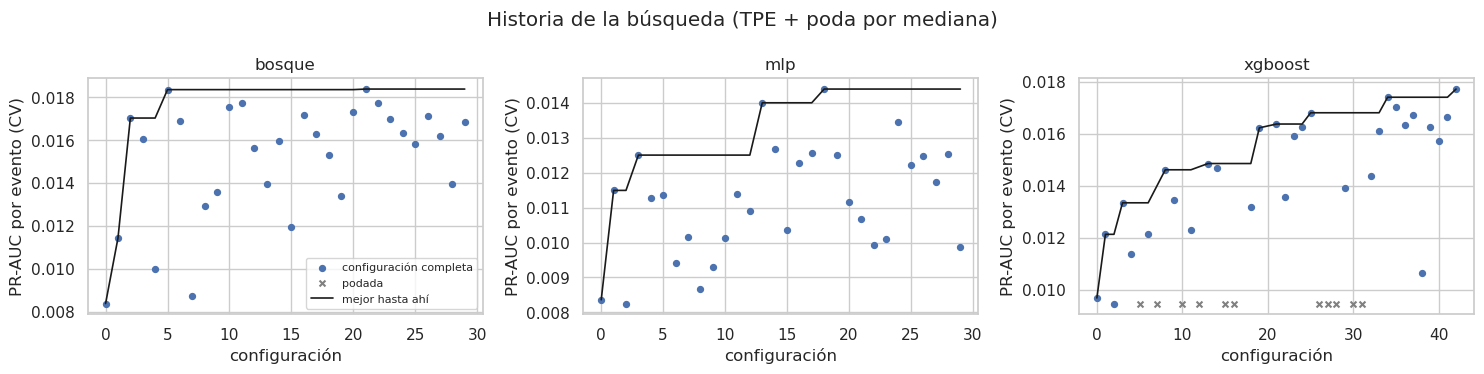

In [4]:
fig, axes = plt.subplots(1, len(FAMILIAS), figsize=(5 * len(FAMILIAS), 3.8), squeeze=False)
for ax, familia in zip(axes[0], FAMILIAS):
    df = tuning.resumen_estudio(ESTUDIOS[familia]).sort_values("number")
    completos = df[df["state"] == "COMPLETE"]
    ax.scatter(completos["number"], completos["value"], s=18, label="configuración completa")
    podados = df[df["state"] == "PRUNED"]
    ax.scatter(podados["number"], np.full(len(podados), completos["value"].min()), marker="x", color="grey",
               s=18, label="podada")
    ax.plot(completos["number"], completos["value"].cummax(), color="k", lw=1.2, label="mejor hasta ahí")
    ax.set_title(familia); ax.set_xlabel("configuración"); ax.set_ylabel("PR-AUC por evento (CV)")
axes[0][0].legend(fontsize=8)
fig.suptitle("Historia de la búsqueda (TPE + poda por mediana)")
fig.tight_layout(); fig.savefig(FIG / "04_historia_tuning.png", dpi=150); plt.show()

In [5]:
for familia in FAMILIAS:
    st = ESTUDIOS[familia]
    try:
        imp = optuna.importance.get_param_importances(st)
        print(f"{familia} · importancia de hiperparámetros (fANOVA):",
              ", ".join(f"{k} {v:.2f}" for k, v in imp.items()))
    except Exception as e:  # noqa: BLE001 - con pocas configuraciones completas fANOVA puede fallar
        print(f"{familia}: importancia no disponible ({type(e).__name__})")
    cols = ["number", "value", "state"] + [c for c in tuning.resumen_estudio(st).columns if c.startswith("params_")]
    display(tuning.resumen_estudio(st)[cols].head(5))

bosque · importancia de hiperparámetros (fANOVA): max_depth 0.83, n_estimators 0.07, colsample_bynode 0.06, subsample 0.02, reg_lambda 0.02, min_child_weight 0.01


,number,value,state,params_colsample_bynode,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_lambda,params_subsample
21,21,0.0184,COMPLETE,0.0626,6,35.4327,331,11.0074,0.5390
5,5,0.0184,COMPLETE,0.4241,7,166.7049,297,11.0151,0.3390
22,22,0.0177,COMPLETE,0.0715,6,24.7777,346,10.6973,0.6230
11,11,0.0177,COMPLETE,0.0570,6,43.3208,315,6.3351,0.5363
10,10,0.0175,COMPLETE,0.0557,6,38.6775,317,6.8886,0.5167


mlp · importancia de hiperparámetros (fANOVA): pos_weight 0.45, dropout 0.16, arquitectura 0.14, weight_decay 0.10, batch_size 0.09, lr 0.03, max_epochs 0.03


,number,value,state,params_arquitectura,params_batch_size,params_dropout,params_lr,params_max_epochs,params_pos_weight,params_weight_decay
18,18,0.0144,COMPLETE,512-256,16384,0.0879,0.0003,8,7.3042,0.0000
13,13,0.0140,COMPLETE,512-256,16384,0.0066,0.0004,10,13.6050,0.0001
24,24,0.0135,COMPLETE,512-256,16384,0.0936,0.0006,8,11.8994,0.0000
14,14,0.0127,COMPLETE,512-256,65536,0.0324,0.0004,10,5.2301,0.0001
17,17,0.0126,COMPLETE,512-256,65536,0.0016,0.0004,8,9.7246,0.0010


xgboost · importancia de hiperparámetros (fANOVA): max_depth 0.72, learning_rate 0.09, colsample_bytree 0.08, min_child_weight 0.06, gamma 0.01, subsample 0.01, n_estimators 0.01, reg_alpha 0.01, reg_lambda 0.00


,number,value,state,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample
42,42,0.0177,COMPLETE,0.6565,3.0994,0.0100,3,19.9279,247,8.4188,0.1209,0.6103
34,34,0.0174,COMPLETE,0.7415,3.0849,0.0131,4,38.6051,344,0.2271,0.0023,0.6534
35,35,0.0170,COMPLETE,0.7534,0.1087,0.0127,3,20.3776,398,1.2102,0.0026,0.6395
25,25,0.0168,COMPLETE,0.6985,0.7655,0.0104,4,30.6802,506,0.3297,0.0038,0.6715
37,37,0.0167,COMPLETE,0.6242,2.9975,0.0120,3,22.1370,434,0.9412,0.0025,0.5676


## 3. La mejor configuración, con el protocolo del notebook 03

La búsqueda usó el 5 % de los discos sanos para entrenar. Para comparar con la versión por defecto de forma justa, la
mejor configuración de cada familia se reentrena con **exactamente el mismo protocolo del notebook 03** (15 % de sanos,
misma CV, misma semilla) y se registra como `<familia>_optimizado` (`fase=tuning`).

In [6]:
CTX_FINAL = exp.preparar(DATOS, DATOS / "oof" / "04", frac_sanos=FRAC_FINAL)
OPTIMIZADOS = {}
for familia in FAMILIAS:
    st = ESTUDIOS[familia]
    params = tuning.ESPACIOS[familia](optuna.trial.FixedTrial(st.best_params))  # hiperparámetros del modelo
    OPTIMIZADOS[familia] = exp.correr(
        CTX_FINAL, f"{familia}_optimizado", "tuning", familia, params=params,
        tags={"rol": "mejor_configuracion", "trial_origen": str(st.best_trial.number)},
        params_registro={f"hp_{k}": v for k, v in st.best_params.items()})

/opt/conda/lib/python3.12/site-packages/xgboost/core.py:705: UserWarning: [12:30:58] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1748362148159/work/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


2026/11/19 13:16:26 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/19 13:16:26 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/19 13:16:29 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/19 13:16:29 INFO mlflow.models.model: Found the following environment variables used during model inference: [ANTHROPIC_API_KEY, GEMINI_API_KEY]. Please check if you need to set them when deploying the model. To disable this message, set environment variable `MLFLOW_RECORD_ENV_VARS_IN_MODEL_LOGGING` to `false`.


🏃 View run bosque_optimizado at: http://mlflow:5000/#/experiments/2/runs/94c701b0979c4571af4090652eff8861
🧪 View experiment at: http://mlflow:5000/#/experiments/2


... (5 outputs left out)

2026/11/19 15:10:55 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/19 15:10:55 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


🏃 View run xgboost_optimizado at: http://mlflow:5000/#/experiments/2/runs/01d872ac943c4a82803021a442e6a852
🧪 View experiment at: http://mlflow:5000/#/experiments/2


xgboost_optimizado: CV 0.0205 ± 0.0192 · train 0.0705 · 50.5 min · run 01d872ac


In [7]:
filas = []
for familia in FAMILIAS:
    base, opt = candidatos_03.loc[familia], OPTIMIZADOS[familia]
    delta = opt["cv_pr_auc_evento_media"] - base["cv_pr_auc_evento_media"]
    filas.append({"familia": familia,
                  "cv_por_defecto": base["cv_pr_auc_evento_media"], "std_por_defecto": base["cv_pr_auc_evento_std"],
                  "cv_optimizado": opt["cv_pr_auc_evento_media"], "std_optimizado": opt["cv_pr_auc_evento_std"],
                  "mejora": delta, "mejora_relativa": delta / base["cv_pr_auc_evento_media"],
                  "mejora_supera_std": delta > base["cv_pr_auc_evento_std"],
                  # Criterio estricto: la mejora debe superar la MAYOR de las dos desviaciones entre pliegues
                  "mejora_supera_std_mayor": delta > max(base["cv_pr_auc_evento_std"], opt["cv_pr_auc_evento_std"]),
                  # Comparación pareada: en cuántos de los 4 pliegues el optimizado supera al de por defecto
                  "pliegues_que_mejoran": sum(o > b for o, b in zip(opt["cv_pliegues"], base["cv_pliegues"])),
                  "train_optimizado": opt["train_pr_auc_evento"], "brecha_optimizado": opt["brecha_train_cv"]})
comparacion = pd.DataFrame(filas).set_index("familia")
Path("../docs/tuning_resultado.json").write_text(json.dumps({
    familia: {"mejores_hiperparametros": ESTUDIOS[familia].best_params, "trial": ESTUDIOS[familia].best_trial.number,
              "run_id_optimizado": OPTIMIZADOS[familia]["run_id"],
              **{k: (bool(v) if isinstance(v, (bool, np.bool_)) else float(v))
                 for k, v in comparacion.loc[familia].items()}}
    for familia in FAMILIAS}, indent=2, ensure_ascii=False))
print(f"Tiempo total del notebook: {(time.time()-T0)/60:.1f} min")
comparacion

Tiempo total del notebook: 169.1 min


,cv_por_defecto,std_por_defecto,cv_optimizado,std_optimizado,mejora,mejora_relativa,mejora_supera_std,mejora_supera_std_mayor,pliegues_que_mejoran,train_optimizado,brecha_optimizado
familia,,,,,,,,,,,
bosque,0.0120,0.0097,0.0203,0.0174,0.0082,0.6841,False,False,4,0.0904,0.0702
mlp,0.0109,0.0062,0.0152,0.0129,0.0042,0.3885,False,False,3,0.1831,0.1679
xgboost,0.0099,0.0045,0.0205,0.0192,0.0107,1.0816,True,False,4,0.0705,0.0499


## 4. Conclusiones

| # | Hallazgo | Evidencia | Consecuencia |
|---|---|---|---|
| 1 | **Las tres familias tienen 30 configuraciones con CV completa** | Bosque 30/30 y MLP 30/30 en estudios nuevos sin poda (`pset3-bosque-v2`, `pset3-mlp-v2`). XGBoost tiene 30 completas más las 11 podadas de la primera ronda (41 en total). Cada configuración completa tiene su modelo en MLflow | El mejor de cada familia sale de 30 configuraciones evaluadas con la CV entera |
| 2 | **La media de CV sube en las tres familias** | Bosque 0,0120 → 0,0203 (+0,0082), MLP 0,0109 → 0,0152 (+0,0042), XGBoost 0,0099 → 0,0205 (+0,0107), con el mismo protocolo del notebook 03 | Las versiones optimizadas pasan al notebook 05 |
| 3 | **Con el criterio estricto, ninguna mejora es demostrable** | Contra la desviación del modelo por defecto solo pasa XGBoost (0,0107 > 0,0045). Contra la mayor de las dos desviaciones no pasa ninguna: 0,0082 < 0,0174, 0,0042 < 0,0129 y 0,0107 < 0,0192 (`mejora_supera_std_mayor`). La desviación del modelo optimizado crece junto con su media | Según la regla del PSet ("si la mejora es menor que la desviación entre pliegues, no se considera mejora"), el tuning **no demuestra una mejora**. La lectura pareada (`pliegues_que_mejoran`) no depende de la deriva entre pliegues y es más favorable: XGBoost y el bosque mejoran en los 4 pliegues y la MLP en 3 de 4. Es un indicio a favor del tuning en los árboles, pero con solo 4 pliegues no alcanza para afirmar una mejora |
| 4 | **El tuning redujo el sobreajuste de los árboles, no el de la MLP** | Brecha entrenamiento − CV: bosque 0,1775 → 0,0702 y XGBoost 0,2093 → 0,0499. En la MLP creció: 0,1423 → 0,1679 | Ganan las configuraciones más regularizadas: profundidad 6 en el bosque y 3 en XGBoost, con un learning rate de 0,010. La profundidad es el hiperparámetro más importante en los dos (fANOVA 0,83 y 0,72). En la MLP el que más pesa es `pos_weight` (0,45) |
| 5 | **La búsqueda con 5 % de discos sanos subestima al protocolo de 15 %** | Mejor configuración en la búsqueda / reentrenada: bosque 0,0184 / 0,0203, XGBoost 0,0177 / 0,0205, MLP 0,0144 / 0,0152 | Lo que se reporta y se compara es siempre el valor reentrenado con el 15 %. El orden entre familias es el mismo con los dos protocolos |
| 6 | **Tras el tuning, los modelos alcanzan a la regla pero no la superan con claridad en la CV** | XGBoost optimizado 0,0205 ± 0,0192 y bosque optimizado 0,0203 ± 0,0174, contra 0,0155 ± 0,0181 de la regla R_198 | La diferencia con el baseline de negocio (0,005) es menor que cualquiera de las desviaciones. El notebook 05 compara en la prueba y en costo |
